#Preparação do ambiente

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [32]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

CAMINHO_BASE = Path("/content/drive/MyDrive/ifes_projeto")
df_pandas = pd.read_csv(CAMINHO_BASE /"ifes_1996_2026.csv")

In [33]:
#Visualização parcial dos dados da base
df_pandas.info()
display(df_pandas.head())
display(df_pandas.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   ano                                              31 non-null     int64  
 1   investimento_total_ifes_bilhoes_brl              31 non-null     float64
 2   investimento_assistencia_estudantil_bilhoes_brl  31 non-null     float64
 3   num_vagas_estudantes                             31 non-null     int64  
 4   num_vagas_docente                                31 non-null     int64  
 5   num_vagas_tae                                    31 non-null     int64  
 6   num_terceirizados                                31 non-null     int64  
dtypes: float64(2), int64(5)
memory usage: 1.8 KB


,ano,investimento_total_ifes_bilhoes_brl,investimento_assistencia_estudantil_bilhoes_brl,num_vagas_estudantes,num_vagas_docente,num_vagas_tae,num_terceirizados
0,1996,32.1,0.02,342100,26800,43100,8200
1,1997,31.8,0.02,351400,27100,42800,8600
2,1998,30.5,0.03,362900,27400,42100,9100
3,1999,29.8,0.03,375200,27600,41500,9800
4,2000,31.2,0.04,391800,28100,41900,10400


,count,mean,std,min,25%,50%,75%,max
ano,31.0,2011.000000,9.092121,1996.00,2003.50,2011.00,2018.50,2026.00
investimento_total_ifes_bilhoes_brl,31.0,53.019355,15.830802,29.80,34.35,54.10,65.95,76.50
investimento_assistencia_estudantil_bilhoes_brl,31.0,0.693548,0.534749,0.02,0.07,0.92,1.21,1.32
num_vagas_estudantes,31.0,896758.064516,400867.766871,342100.00,465950.00,984500.00,1305000.00,1385000.00
num_vagas_docente,31.0,64316.129032,28928.787240,26800.00,30650.00,73100.00,92850.00,98100.00
num_vagas_tae,31.0,61212.903226,14261.410448,41500.00,43800.00,69800.00,73150.00,77400.00
num_terceirizados,31.0,34812.903226,18120.425711,8200.00,14300.00,41200.00,48850.00,59100.00


#Inicio

##Etapa 2.1

In [34]:
#Ordens de grandeza de cada coluna da base de dados
invest_em_reais = df_pandas.drop(columns="ano").copy()
colunas_mod = ['investimento_total_ifes_bilhoes_brl', 'investimento_assistencia_estudantil_bilhoes_brl']
invest_em_reais[colunas_mod] = invest_em_reais[colunas_mod]*1e9 #Convertendo de bilhões de reais para reais (mesma unidade de medida)

print (invest_em_reais.median().apply(lambda x : 10**np.floor(np.log10(x))))


investimento_total_ifes_bilhoes_brl                1.000000e+10
investimento_assistencia_estudantil_bilhoes_brl    1.000000e+08
num_vagas_estudantes                               1.000000e+05
num_vagas_docente                                  1.000000e+04
num_vagas_tae                                      1.000000e+04
num_terceirizados                                  1.000000e+04
dtype: float64


Observa-se acima a ordem de grandeza da mediana de cada uma das variáveis presentes na base de dados original. Pela análise da mediana dos dados, pode-se observar que se distribuem sob quatro ordens de grandeza: 10^10, 10^8, 10^5 e 10^4, com uma "amplitude" de até 1.000.000x (ou 10^6) entre o número de terceirizados (ordem de 10^4) e o investimento total dos ifes (ordem de 10^10). Vale observar que uma possível comparação entre num_terceirizados e investimento deve levar em conta, além da disparidade nas ordens de grandeza, as diferentes unidades de medida (terceirizados e reais, respectivamente).

##Etapa 2.2

In [74]:
#Optou-se pela análise de décadas
df_pandas["decada"] = (df_pandas["ano"]//10) * 10

colunas = ["num_vagas_estudantes", "num_vagas_docente", "num_vagas_tae", "num_terceirizados", "investimento_total_ifes_bilhoes_brl", "investimento_assistencia_estudantil_bilhoes_brl"]

grupos = df_pandas.groupby("decada")
crescimento = grupos[colunas].last() - grupos[colunas].first()
crescimento.insert(0, "Período", grupos["ano"].first().astype(str) + "-" + grupos["ano"].last().astype(str))

crescimento = crescimento.rename(columns={
    "investimento_total_ifes_bilhoes_brl" : "Investimento total (bilhões R$)",
    "investimento_assistencia_estudantil_bilhoes_brl" : "Investimento assistência estudantil (bilhões R$)",
    "num_vagas_estudantes" : "Vagas de estudantes",
    "num_vagas_docente" : "Vagas de docentes",
    "num_vagas_tae" : "Vagas de técnicos (TAE)",
    "num_terceirizados" : "Terceirizados"
})

display(crescimento.style.set_caption("Variação de vagas e investimento entre o último e o primeiro ano de cada período"))

,Período,Vagas de estudantes,Vagas de docentes,Vagas de técnicos (TAE),Terceirizados,Investimento total (bilhões R$),Investimento assistência estudantil (bilhões R$)
decada,,,,,,,
1990,1996-1999,33100,800,-1600,1600,-2.300000,0.010000
2000,2000-2009,423100,31300,20200,31400,35.600000,0.570000
2010,2010-2019,409900,25900,7400,-1800,-11.300000,0.400000
2020,2020-2026,61000,4300,-600,3500,8.400000,0.070000


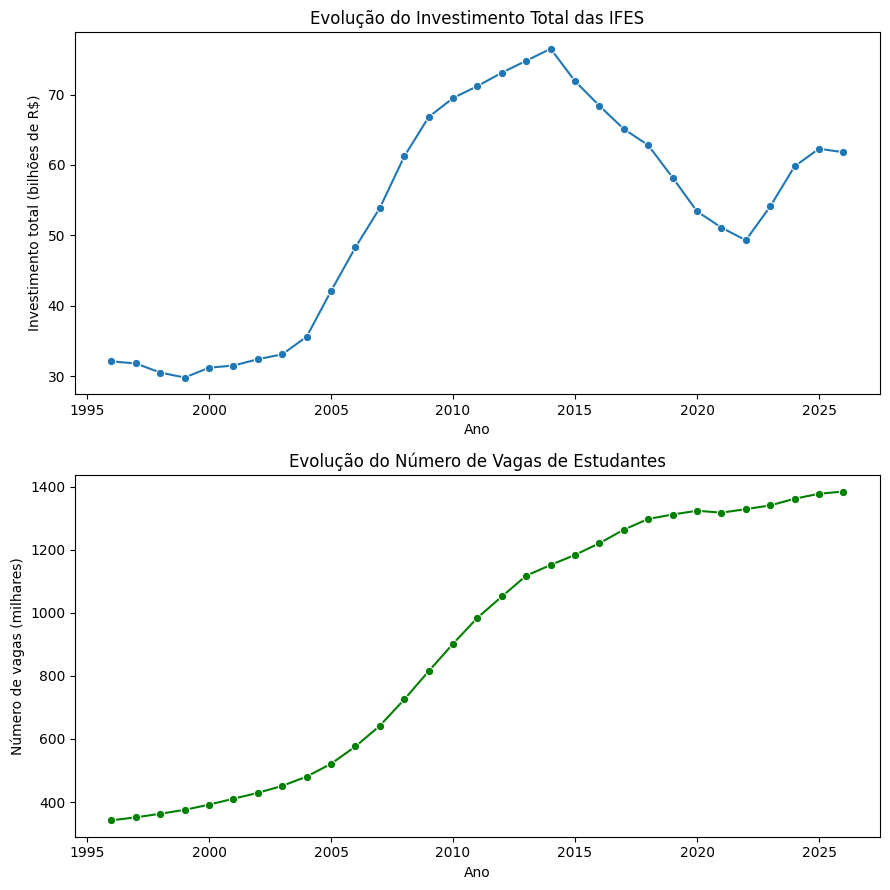

In [81]:
#Plottagem: Evolução do investimento total e do número de vagas de estudantes ao longo dos anos
fig, grafico = plt.subplots(2, 1, figsize=(9, 9))

# Gráfico 1 - Investimento total
grafico[0].set_title('Evolução do Investimento Total das IFES')
grafico[0].set_xlabel('Ano')
grafico[0].set_ylabel('Investimento total (bilhões de R$)')

sns.lineplot(
    data=df_pandas,
    x='ano',
    y='investimento_total_ifes_bilhoes_brl',
    marker='o', #adiciona círculos sobre a linha ao longo dos anos
    ax=grafico[0]
)

# Gráfico 2 - Vagas de estudantes
grafico[1].set_title('Evolução do Número de Vagas de Estudantes')
grafico[1].set_xlabel('Ano')
grafico[1].set_ylabel('Número de vagas (milhares)')

sns.lineplot(
    data=df_pandas,
    x='ano',
    y=df_pandas['num_vagas_estudantes'] / 1e3,
    marker='o',
    color='green',
    ax=grafico[1]
)

plt.tight_layout()
plt.show()

Para a análise da evolução do investimento total das IFES e do número de vagas de estudantes, optou-se por representações independentes devido às diferentes ordens de grandeza e unidades dos dados (reais e vagas, respectivamente). Para a exposição dos dados foi escolhido o gráfico de linhas, por ser um modelo bastante eficiente na comunicação visual da variação absoluta de dados numéricos ao longo dos anos. Além disso, as duas grandezas foram representadas com cores distintas e facilmente diferenciáveis (verde e azul), objetivando maior clareza.

##Etapa 2.3

In [75]:
#Cálculo da relação de proporção entre vagas de estudante por vagas de docente/TAE
df_pandas["estudante_por_docente"] = df_pandas["num_vagas_estudantes"] / df_pandas["num_vagas_docente"]
df_pandas["estudante_por_tae"] = df_pandas["num_vagas_estudantes"] / df_pandas["num_vagas_tae"]
display(df_pandas[["ano", "estudante_por_docente", "estudante_por_tae"]].round(2).style.set_caption("Relação de vagas de estudante por vaga de docente/TAE"))

,ano,estudante_por_docente,estudante_por_tae
0,1996,12.760000,7.940000
1,1997,12.970000,8.210000
2,1998,13.240000,8.620000
3,1999,13.590000,9.040000
4,2000,13.940000,9.350000
5,2001,14.200000,9.700000
6,2002,14.600000,10.030000
7,2003,14.990000,10.400000
8,2004,15.400000,10.870000
9,2005,15.110000,11.140000


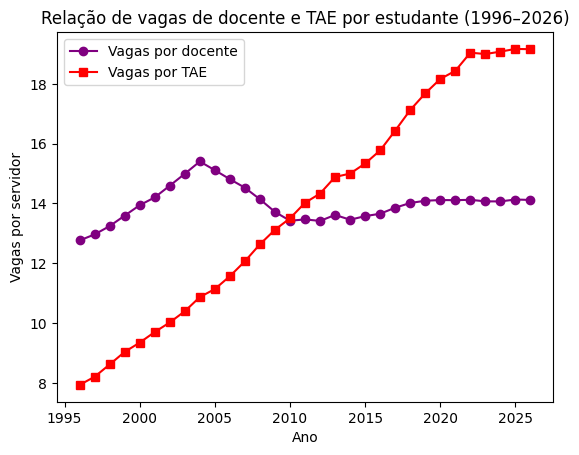

In [55]:
plt.plot(df_pandas["ano"], df_pandas["estudante_por_docente"], marker="o", label="Vagas por docente", color="purple")
plt.plot(df_pandas["ano"], df_pandas["estudante_por_tae"], marker="s", label="Vagas por TAE", color="red")

plt.title("Relação de vagas de docente e TAE por estudante (1996–2026)")
plt.xlabel("Ano")
plt.ylabel("Vagas por servidor")
plt.legend()
plt.show()

Para apresentar as relações de vaga entre estudante e docente e estudante e TAE foi escolhido o gráfico de linhas, por permitir uma visualização clara e objetiva das variações de vaga (grandeza numérica) por servidor ao longo da faixa de anos definida (1996-2026). Além disso, a escolha de um único gráfico para representar as duas relações é bastante útil, permitindo a comparação direta entre ambas. Outro ponto a apontar-se foi a escolha de cores facilmente diferenciáveis e a inclusão de figuras geométricas sobre a linha facilitando a comparação ano a ano.

##Etapa 2.4

In [69]:
#Separando os dados por períodos de mandato presidencial
periodos = [
    df_pandas["ano"] <= 1998,
    df_pandas["ano"] <= 2002,
    df_pandas["ano"] <= 2006,
    df_pandas["ano"] <= 2010,
    df_pandas["ano"] <= 2014,
    df_pandas["ano"] <= 2016,
    df_pandas["ano"] <= 2018,
    df_pandas["ano"] <= 2022,
    df_pandas["ano"] <= 2026,
]

correspondencias = [
    "1996-1998",
    "1999-2002",
    "2003-2006",
    "2007-2010",
    "2011-2014",
    "2015-2016",
    "2017-2018",
    "2019-2022",
    "2023-2026",
]

df_pandas["periodo_gov"] = np.select(
    periodos,
    correspondencias,
    default="Sem correspondência"
)

In [73]:
estatisticas = df_pandas.groupby("periodo_gov").agg(
    media_assist = ("investimento_assistencia_estudantil_bilhoes_brl", "mean"),
    mediana_assist = ("investimento_assistencia_estudantil_bilhoes_brl", "median"),
    soma_assist = ("investimento_assistencia_estudantil_bilhoes_brl", "sum"),
    media_vagas_abertas = ("num_vagas_estudantes", "mean"),
    mediana_vagas_abertas = ("num_vagas_estudantes", "median"),
    soma_vagas_abertas = ("num_vagas_estudantes", "sum"),
)

estatisticas = estatisticas.rename(columns={
    "media_assist": "Média (bilhões R$)",
    "mediana_assist": "Mediana (bilhões R$)",
    "soma_assist": "Total (bilhões R$)",
    "media_vagas_abertas": "Média de vagas",
    "mediana_vagas_abertas": "Mediana de vagas",
    "soma_vagas_abertas": "Total de vagas"
})

formatacao = {
    "Média (bilhões R$)": "{:.3f}",
    "Mediana (bilhões R$)": "{:.3f}",
    "Total (bilhões R$)": "{:.3f}",
    "Média de vagas": "{:,.0f}",
    "Mediana de vagas": "{:,.0f}",
    "Total de vagas": "{:,.0f}"
}


display(estatisticas.style.format(formatacao, thousands= ".", decimal=",").set_caption("Estatísticas de investimentos e vagas por mandato presidencial (1996-2026)"))

,Média (bilhões R$),Mediana (bilhões R$),Total (bilhões R$),Média de vagas,Mediana de vagas,Total de vagas
periodo_gov,,,,,,
1996-1998,"0,023","0,020","0,070",352.133,351.400,1.056.400
1999-2002,"0,040","0,040","0,160",401.650,401.150,1.606.600
2003-2006,"0,110","0,100","0,440",507.375,501.000,2.029.500
2007-2010,"0,515","0,515","2,060",771.125,770.150,3.084.500
2011-2014,"1,143","1,165","4,570",1.076.625,1.085.000,4.306.500
2015-2016,"1,285","1,285","2,570",1.202.500,1.202.500,2.405.000
2017-2018,"1,235","1,235","2,470",1.281.000,1.281.000,2.562.000
2019-2022,"1,100","1,120","4,400",1.320.750,1.321.000,5.283.000
2023-2026,"1,190","1,215","4,760",1.366.500,1.370.000,5.466.000


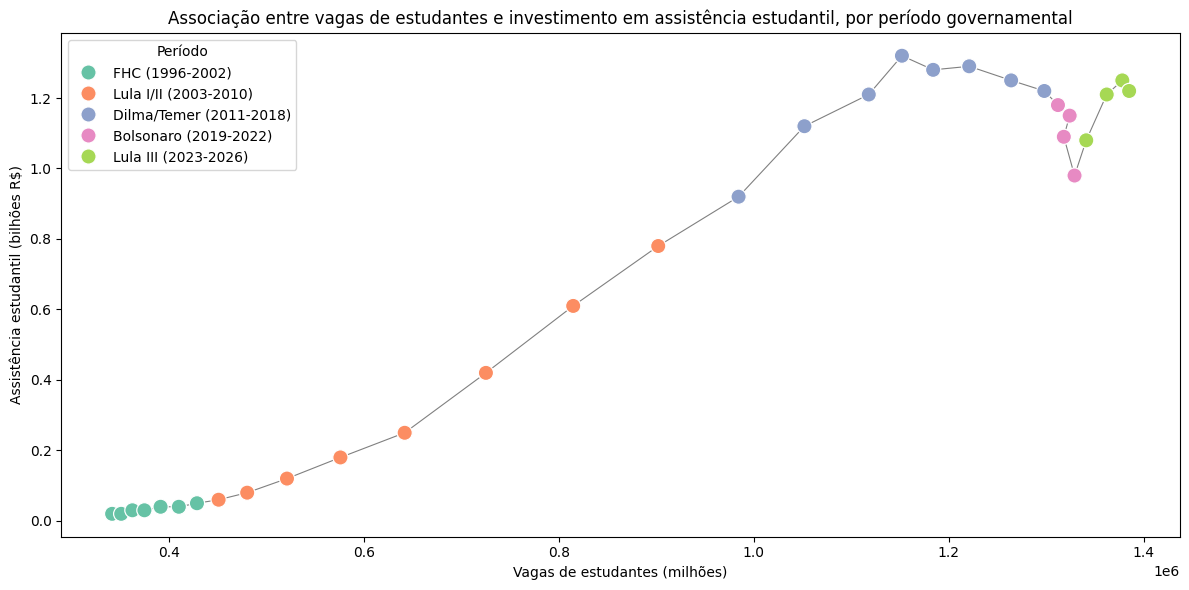

In [106]:

#Classificando anos por governo (presidente)
periodos = [
    df_pandas["ano"] <= 2002,
    df_pandas["ano"] <= 2010,
    df_pandas["ano"] <= 2018,
    df_pandas["ano"] <= 2022,
    df_pandas["ano"] <= 2026,
]

correspondencias = [
    "FHC (1996-2002)",
    "Lula I/II (2003-2010)",
    "Dilma/Temer (2011-2018)",
    "Bolsonaro (2019-2022)",
    "Lula III (2023-2026)",
]

df_pandas["governo"] = np.select(
    periodos,
    correspondencias,
    default="Sem correspondência"
)


fig, eixo = plt.subplots(figsize=(12, 6))

#Linha conectando cada ano
eixo.plot(df_pandas["num_vagas_estudantes"],
        df_pandas["investimento_assistencia_estudantil_bilhoes_brl"],
        color="gray", lw=0.8, zorder=0) #lw controla a espessura da linha e zorder define a "camada" em que a linha estará (para não se sobrepor aos outros elementos)

sns.scatterplot(
    data=df_pandas,
    x="num_vagas_estudantes",
    y="investimento_assistencia_estudantil_bilhoes_brl",
    hue="governo", #Define que as cores devem variar conforme a variável "governo" varia
    palette="Set2", #Define a paleta de cores usada (escolha arbitrária)
    s=120, #Métrica do tamanho de cada círculo
    ax=eixo, #Define que o gráfico deve ser desenhado sobre o eixo que contém a linha de conexão desenhada anteriormente
)

#Informações visuais do gráfico
eixo.set_xlabel("Vagas de estudantes (milhões)")
eixo.set_ylabel("Assistência estudantil (bilhões R$)")
eixo.set_title("Associação entre vagas de estudantes e investimento em assistência estudantil, por período governamental")
eixo.legend(title="Período", loc="upper left")

plt.tight_layout()
plt.show()

Foi escolhido o scatter plot para avaliar a relação entre vagas de estudantes e investimento em assistência estudantil ao longo dos anos, por permitir uma avaliação clara da proporcionalidade do crescimento entre essas duas variáveis, que estaria implícita num heat map, por exemplo. Foi utilizada, além das duas variáveis mencionadas, uma terceira (qualitativa) diferenciada por cores, que diz respeito ao governo que compreende cada faixa do gráfico.
Pela análise do gráfico, pode-se observar uma não proporcionalidade e inconstância entre as variáveis ao longo dos anos. Até o ano de 2014 os investimentos em assistência estudantil aparentemente acompanhavam o crescimento em vagas de estudantes, mas, de 2015 em diante houveram cortes/estagnações consecutivas, levando o gráfico à um mínimo local em 2022.

##Etapa 2.5